## Topic Analysis

In [86]:
import pyarrow.parquet as pq

data_lang_detected = pq.read_table("../data/data_with_lang_detection.parquet").to_pandas()

### 1st topic modeling techinque: using only text (name + description) of each token

In [87]:
import re

def clean_text_bertopic(text: str) -> str:
    """
    Clean the text for BERTopic analysis.
    """
    # Remove URLs
    text = re.sub(r"http\S+|www\S+|https\S+|discord\S+", "", text)

    return text

Drop non-english texts:

In [88]:
data = data_lang_detected[data_lang_detected["is_english"] == True]

Remove URLs and drop where text for BERTopic is " "

In [89]:
docs = data["meta_name_description"].apply(clean_text_bertopic).tolist()
data["cleaned_text_bertopic"] = docs
data = data.loc[data["cleaned_text_bertopic"] != " "]

In [91]:
data["word_count"] = data["cleaned_text_bertopic"].apply(lambda x: len(x.split()))

In [92]:
data["character_count"] = data["cleaned_text_bertopic"].apply(lambda x: len(x))

In [41]:
import numpy as np

char_counts = [len(doc) for doc in docs]
word_punctuation_emojis_counts = [len(doc.split()) for doc in docs]
word_count = [re.findall(r'\w+', doc) for doc in docs]
word_count = [len(words) for words in word_count]

# Compute mean and standard_deviation
char_mean = np.mean(char_counts)
char_std = np.std(char_counts)

word_punctuation_emojis_counts_mean = np.mean(word_punctuation_emojis_counts)
word_punctuation_emojis_counts_std = np.std(word_punctuation_emojis_counts)

word_count_mean = np.mean(word_count)
word_count_std = np.std(word_count)

print(f"Character Count - Mean: {char_mean}, Std: {char_std}")
print(f"Word Count (with punctuation and emojis) - Mean: {word_punctuation_emojis_counts_mean}, Std: {word_punctuation_emojis_counts_std}")
print(f"Word Count - Mean: {word_count_mean}, Std: {word_count_std}")

Character Count - Mean: 54.01238068977362, Std: 144.72872890351744
Word Count (with punctuation and emojis) - Mean: 8.984381349039424, Std: 25.730453235311796
Word Count - Mean: 9.1057464139004, Std: 26.08550446676279


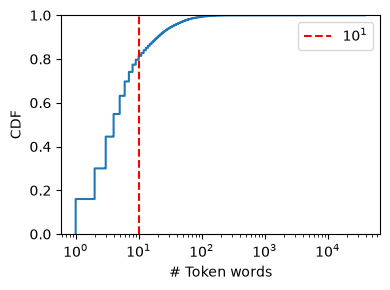

In [112]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(4, 3))
sns.ecdfplot(data=data, x="word_count", log_scale=True)

# Add vertical line at 10^1 (10)
plt.axvline(x=10, color="red", linestyle="--", linewidth=1.5, label="$10^1$")

plt.xlabel("# Token words")
plt.ylabel("CDF")

plt.tight_layout()
plt.legend()
plt.savefig("../reports/figures/word_count_cdf.pdf")
plt.show()

In [109]:
# Take the min and max value of word_count
max_word_count = data["word_count"].max()
min_word_count = data["word_count"].min()

max_word_count, min_word_count

(np.int64(39848), np.int64(1))

In [5]:
from sentence_transformers import SentenceTransformer

embedding_model = SentenceTransformer("all-MiniLM-L6-v2")

/home/danielnj/Crypto-Analysis/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 12132.14it/s]


In [ ]:
embeddings = embedding_model.encode(
    docs, show_progress_bar=True, normalize_embeddings=True,
)

/home/danielnj/Crypto-Analysis/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Batches: 100%|██████████| 139739/139739 [06:05<00:00, 381.99it/s]


In [5]:
import numpy

embeddings = numpy.load("../models/embedding/embeddings.npy")

Run BERTopic first for a sample:

In [ ]:
import numpy as np

search_size = min(100000, len(docs))

rng = np.random.default_rng(42)
search_indices = rng.choice(len(docs), size=search_size, replace=False)

search_docs = [docs[i] for i in search_indices]
search_embeddings = embeddings[search_indices]

Parameter grid:

In [64]:
from sklearn.model_selection import ParameterGrid

parameter_grid = {
    "umap_n_neighbors": [50, 100, 200],
    "umap_min_dist": [0.0, 0.05],
    "hdbscan_min_cluster_size": [50, 100, 200],
    "hdbscan_min_samples": [10, 20],
}

In [7]:
from bertopic import BERTopic
from sklearn.feature_extraction.text import CountVectorizer
from bertopic.vectorizers import ClassTfidfTransformer
from sklearn.metrics import silhouette_score
from cuml.cluster import HDBSCAN
from cuml.manifold import UMAP
import pandas as pd

from tqdm import tqdm

Grid Search

In [ ]:
results = []
grid = list(ParameterGrid(parameter_grid))

for params in tqdm(grid, total=len(grid), desc="BERTopic grid search"):
    umap_model = UMAP(
        n_neighbors=params["umap_n_neighbors"], # Controls how UMAP balances local versus global structure in the data. Smaller values focus on local structure, while larger values capture more global structure.
        n_components=5, # Dimensionality of the reduced dimension space. 
        min_dist=params["umap_min_dist"], # Controls how tightly UMAP packs points together.
        metric="cosine", # Metric to compute distances in the input space. "cosine" is often used for text embeddings.
        random_state=42,
    )

    hdbscan_model = HDBSCAN(
        min_cluster_size=params["hdbscan_min_cluster_size"], # Minimum number of samples in a cluster for the cluster to be considered a valid cluster.
        min_samples=params["hdbscan_min_samples"], # Higher values results on more points labeled as noise.
        metric="euclidean", # Euclidean is often used after the dimensionality is reduced by UMAP.
        cluster_selection_method="eom", # Excess of Mass favors large, broad clusters
        prediction_data=True,
    )

    vectorizer_model = CountVectorizer(
        max_df = 0.9, # Ignore terms that appear in more than 90% of the documents.
        min_df = 0.1, # Ignore terms that appear in less than 10% of the documents.
    )

    ctfidf_model = ClassTfidfTransformer(
        reduce_frequent_words=True
    )

    topic_model = BERTopic(
        embedding_model=embedding_model,
        umap_model=umap_model,
        hdbscan_model=hdbscan_model,
        vectorizer_model=vectorizer_model,
        ctfidf_model=ctfidf_model,
        calculate_probabilities=False,
        verbose=True,
    )

    topics, _ = topic_model.fit_transform(
        search_docs,
        search_embeddings,
    )

    topics = np.asarray(topics)
    non_outlier_mask = topics != -1
    non_outlier_topics = topics[non_outlier_mask]

    n_topics = len(set(non_outlier_topics))

    # Silhouette requires at least two clusters.
    if (
        non_outlier_mask.sum() == 0
        or n_topics < 2
        or n_topics >= non_outlier_mask.sum()
    ):
        silhouette = np.nan
    else:
        silhouette = silhouette_score(
            search_embeddings[non_outlier_mask],
            non_outlier_topics,
            metric="cosine",
        )

    outlier_rate = float(np.mean(topics == -1))

    results.append({
        **params,
        "n_topics": n_topics,
        "outlier_rate": outlier_rate,
        "silhouette": silhouette,
        "model": topic_model,
    })

results_df = pd.DataFrame(results)

In [ ]:
results_df["coverage"] = 1.0 - results_df["outlier_rate"]

results_df["objective"] = (
    results_df["silhouette"]
    * results_df["coverage"]
)

best_result = (results_df.dropna(subset=["objective"]).sort_values("objective", ascending=False).iloc[0])

In [49]:
best_result

hdbscan_min_cluster_size                                                  500
hdbscan_min_samples                                                       100
umap_min_dist                                                             0.0
umap_n_neighbors                                                          100
n_topics                                                                   24
outlier_rate                                                          0.62453
silhouette                                                            0.11851
model                       BERTopic(calculate_probabilities=False, ctfidf...
coverage                                                              0.37547
objective                                                            0.044497
Name: 7, dtype: object

In [8]:
best_result = {
    "umap_n_neighbors": 100,
    "umap_min_dist": 0.0,
    "hdbscan_min_cluster_size": 500,
    "hdbscan_min_samples": 100,
}

Testing the best_result

In [13]:
best_params = best_result

umap_model = UMAP(
    n_neighbors=best_params["umap_n_neighbors"], # Controls how UMAP balances local versus global structure in the data. Smaller values focus on local structure, while larger values capture more global structure.
    n_components=10, # Dimensionality of the reduced dimension space. 
    min_dist=best_params["umap_min_dist"], # Controls how tightly UMAP packs points together.
    metric="cosine", # Metric to compute distances in the input space. "cosine" is often used for text embeddings.
    random_state=42,
)

hdbscan_model = HDBSCAN(
    min_cluster_size=best_params["hdbscan_min_cluster_size"], # Minimum number of samples in a cluster for the cluster to be considered a valid cluster.
    min_samples=best_params["hdbscan_min_samples"], # Higher values results on more points labeled as noise.
    metric="euclidean", # Euclidean is often used after the dimensionality is reduced by UMAP.
    cluster_selection_method="eom", # Excess of Mass favors large, broad clusters
    prediction_data=True,
)

vectorizer_model = CountVectorizer(
    max_df = 0.9, # Ignore terms that appear in more than 90% of the documents.
    min_df = 0.1, # Ignore terms that appear in less than 10% of the documents.
)

ctfidf_model = ClassTfidfTransformer(
    reduce_frequent_words=True
)

topic_model = BERTopic(
    embedding_model=embedding_model,
    umap_model=umap_model,
    hdbscan_model=hdbscan_model,
    vectorizer_model=vectorizer_model,
    ctfidf_model=ctfidf_model,
    calculate_probabilities=False,
    verbose=True,
)

topics, _ = topic_model.fit_transform(
    search_docs,
    search_embeddings,
)

2026-10-20 13:48:21,465 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm


2026-10-20 13:48:23,215 - BERTopic - Dimensionality - Completed ✓
2026-10-20 13:48:23,218 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-20 13:48:23,526 - BERTopic - Cluster - Completed ✓
2026-10-20 13:48:23,533 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-20 13:48:23,860 - BERTopic - Representation - Completed ✓


In [14]:
topic_model.get_topic_info()

,Topic,Count,Name,Representation,Representative_Docs
0,-1,62656,-1_mayhem_bull_test_solana,"[mayhem, bull, test, solana, fees, built, mark...",[Golden Dragfox **$DRAGFOX — The Golden Dragon...
1,0,5585,0_og_dev_launchblitz_using,"[og, dev, launchblitz, using, hello, check, cl...","[THIS IS THE OG HELLO Launched on , OG HELLO L..."
2,1,4666,1_wojak_charlie_kirk_rip,"[wojak, charlie, kirk, rip, vance, kabuto, mia...",[Wojak 2.0 Official wojak 2.0 by the wojak dev...
3,2,4127,2_penny_currency_coins_bitcoin,"[penny, currency, coins, bitcoin, coinbase, do...",[READ THIS IS INSANE HELLO?? Are you SEEING th...
4,3,2832,3_memecoin_memes_memecoins_culture,"[memecoin, memes, memecoins, culture, internet...",[PEPE ASS COIN Pepe Ass Coin was born from the...
5,4,2238,4_agents_agent_intelligence_autonomous,"[agents, agent, intelligence, autonomous, cryp...",[Moai The Analist Moai is a Claude Opus powere...
6,5,1692,5_pumpfun_pumpportal_via_gooners,"[pumpfun, pumpportal, via, gooners, pumpy, pum...","[Bitdog Token Bitdog created via PumpPortal, A..."
7,6,1471,6_whale_fish_lobster_crab,"[whale, fish, lobster, crab, shark, whales, do...","[The MobyDick Whale , GORLOCK THE WHALE , BADD..."
8,7,1396,7_dog_doge_dogs_puppy,"[dog, doge, dogs, puppy, pup, wif, bark, pet, ...",[GOY DOG Goy Dog is not just another meme dog....
9,8,1238,8_cat_kitty_cats_kitten,"[cat, kitty, cats, kitten, roaring, crew, grum...","[just a cat , just a cat Deployed with , SAWGG..."


In [73]:
# Reducing outliers
new_topics = topic_model.reduce_outliers(search_docs, topics, strategy="c-tf-idf", threshold=0.1)

model_updated = topic_model
model_updated.update_topics(search_docs, topics=new_topics, ctfidf_model=ctfidf_model, vectorizer_model=vectorizer_model)
model_updated.get_topic_info()

2026-10-20 12:23:10,818 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


,Topic,Count,Name,Representation,Representative_Docs
0,-1,59356,-1_mayhem_test_black_epstein,"[mayhem, test, black, epstein, ansem, call, cl...",[Golden Dragfox **$DRAGFOX — The Golden Dragon...
1,0,5595,0_og_launchblitz_using_hello,"[og, launchblitz, using, hello, check, claimed...","[THIS IS THE OG HELLO Launched on , OG HELLO L..."
2,1,4679,1_wojak_charlie_kirk_rip,"[wojak, charlie, kirk, rip, vance, kabuto, mia...",[Wojak 2.0 Official wojak 2.0 by the wojak dev...
3,2,4133,2_penny_currency_coins_bitcoin,"[penny, currency, coins, bitcoin, coinbase, do...",[READ THIS IS INSANE HELLO?? Are you SEEING th...
4,3,3299,3_energy_culture_driven_chaos,"[energy, culture, driven, chaos, internet, mem...",[PEPE ASS COIN Pepe Ass Coin was born from the...
5,4,2437,4_agents_agent_autonomous_intelligence,"[agents, agent, autonomous, intelligence, data...",[Moai The Analist Moai is a Claude Opus powere...
6,5,1748,5_pumpfun_pumpportal_via_airdrop,"[pumpfun, pumpportal, via, airdrop, gooners, p...","[Bitdog Token Bitdog created via PumpPortal, A..."
7,6,1504,6_whale_fish_lobster_crab,"[whale, fish, lobster, crab, shark, whales, oc...","[The MobyDick Whale , GORLOCK THE WHALE , BADD..."
8,7,1565,7_doge_dogs_puppy_pup,"[doge, dogs, puppy, pup, bark, wif, pet, dogwi...",[GOY DOG Goy Dog is not just another meme dog....
9,8,1440,8_cat_kitty_cats_kitten,"[cat, kitty, cats, kitten, roaring, crew, kitt...","[just a cat , just a cat Deployed with , SAWGG..."


In [15]:
best_params

{'umap_n_neighbors': 100,
 'umap_min_dist': 0.0,
 'hdbscan_min_cluster_size': 500,
 'hdbscan_min_samples': 100}

Run 500.000 samples:

In [42]:
import numpy as np

TRAIN_SIZE = 300000

rng = np.random.default_rng(42)
search_indices = rng.choice(len(docs), size=TRAIN_SIZE, replace=False)

train_docs = [docs[i] for i in search_indices]
train_embeddings = embeddings[search_indices]

In [46]:
best_params_500_data = {
    "umap_n_neighbors": 150,
    "umap_min_dist": 0.0,
    "hdbscan_min_cluster_size": 2000,
    "hdbscan_min_samples": 100,
}

In [47]:
final_umap_model = UMAP(
    n_neighbors=best_params_500_data["umap_n_neighbors"], # Controls how UMAP balances local versus global structure in the data. Smaller values focus on local structure, while larger values capture more global structure.
    n_components=10, # Dimensionality of the reduced dimension space. 
    min_dist=best_params_500_data["umap_min_dist"], # Controls how tightly UMAP packs points together.
    metric="cosine", # Metric to compute distances in the input space. "cosine" is often used for text embeddings.
    random_state=42,
)

final_hdbscan_model = HDBSCAN(
    min_cluster_size=best_params_500_data["hdbscan_min_cluster_size"], # Minimum number of samples in a cluster for the cluster to be considered a valid cluster.
    min_samples=best_params_500_data["hdbscan_min_samples"], # Higher values results on more points labeled as noise.
    metric="euclidean", # Euclidean is often used after the dimensionality is reduced by UMAP.
    cluster_selection_method="eom", # Excess of Mass favors large, broad clusters
    prediction_data=True,
)

final_vectorizer_model = CountVectorizer(
    max_df = 0.9, # Ignore terms that appear in more than 90% of the documents.
    min_df = 0.1, # Ignore terms that appear in less than 10% of the documents.
)

final_ctfidf_model = ClassTfidfTransformer(
    reduce_frequent_words=True
)

topic_model = BERTopic(
    embedding_model=embedding_model,
    umap_model=umap_model,
    hdbscan_model=hdbscan_model,
    vectorizer_model=vectorizer_model,
    ctfidf_model=ctfidf_model,
    calculate_probabilities=False,
    verbose=True,
)

train_topics, _ = topic_model.fit_transform(train_docs, train_embeddings)

2026-10-20 14:05:54,208 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm


2026-10-20 14:06:00,470 - BERTopic - Dimensionality - Completed ✓
2026-10-20 14:06:00,475 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-20 14:06:02,704 - BERTopic - Cluster - Completed ✓
2026-10-20 14:06:02,719 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-20 14:06:03,636 - BERTopic - Representation - Completed ✓


In [48]:
topic_model.get_topic_info()

,Topic,Count,Name,Representation,Representative_Docs
0,-1,171884,-1_lucky_call_launchblitz_us,"[lucky, call, launchblitz, us, test, read, mon...",[STRATEGY A girl sits across from a dragon at ...
1,0,8386,0_penny_currency_coins_unstable,"[penny, currency, coins, unstable, useless, te...",[America250 Freedom Coin The America250 Freedo...
2,1,7204,1_memecoin_memes_memecoins_culture,"[memecoin, memes, memecoins, culture, inspired...",[CornHub (Token) Introducing CORnHUb Token — t...
3,2,6108,2_agents_agent_intelligence_x402,"[agents, agent, intelligence, x402, autonomous...",[roboquant.dev RoboQuant is a cloud-based IDE ...
4,3,4749,3_pumpfun_pumpportal_pump_via,"[pumpfun, pumpportal, pump, via, rewards, pump...",[TheMetaInCrypto Token TheMetaInCrypto created...
...,...,...,...,...,...
81,80,532,80_toilet_piss_poop_poo,"[toilet, piss, poop, poo, paper, shit, festiva...","[toilet paper , Toilet Paper Launched on , Gra..."
82,81,527,81_rug_rugpull_pull_rugs,"[rug, rugpull, pull, rugs, pulls, rugged, soft...",[MARKET SOFT RUG Born in a Discord server at 3...
83,82,524,82_mascot_mascots_zcash_tina,"[mascot, mascots, zcash, tina, olympics, 4chan...","[The Unemployment Mascot , The Barça Mascot , ..."
84,83,504,83_free_ez_deer_easy,"[free, ez, deer, easy, cant, disgusting, 200k,...","[READ FREE VAMP Launched on , READ FREE VAMP L..."


In [ ]:
# Batch processing and inference for the entire dataset
BATCH_SIZE = 100_000
all_topics = []

print("Starting batch processing and inference for the entire dataset...")
for i in tqdm(range(0, len(docs), BATCH_SIZE)):
    print(f"Processing batch {i // BATCH_SIZE + 1} of {len(docs) // BATCH_SIZE}...")
    batch_docs = docs[i: i + BATCH_SIZE]
    batch_embeddings = embeddings[i : i + BATCH_SIZE]

    batch_topics, _ = topic_model.transform(batch_docs, embeddings=batch_embeddings)
    all_topics.extend(batch_topics)

all_topics = np.array(all_topics)

topic_model.update_topics(docs, topics=all_topics)

In [50]:
topic_model.get_topic_info()

,Topic,Count,Name,Representation,Representative_Docs
0,-1,2585801,-1_the_on_and_to,"[the, on, and, to, is, of, launched, in, it, for]",[STRATEGY A girl sits across from a dragon at ...
1,0,122740,0_coin_official_this_coins,"[coin, official, this, coins, buy, launched, o...",[America250 Freedom Coin The America250 Freedo...
2,1,106590,1_memecoin_meme_memes_community,"[memecoin, meme, memes, community, and, the, o...",[CornHub (Token) Introducing CORnHUb Token — t...
3,2,81932,2_ai_agent_agents_intelligence,"[ai, agent, agents, intelligence, autonomous, ...",[roboquant.dev RoboQuant is a cloud-based IDE ...
4,3,74268,3_pump_pumpfun_fun_pumpportal,"[pump, pumpfun, fun, pumpportal, via, token, c...",[TheMetaInCrypto Token TheMetaInCrypto created...
...,...,...,...,...,...
81,80,7631,80_poop_toilet_piss_pee,"[poop, toilet, piss, pee, poo, pisscoin, skibi...","[toilet paper , Toilet Paper Launched on , Gra..."
82,81,7670,81_rug_rugs_pull_rugpull,"[rug, rugs, pull, rugpull, no, rugger, rugged,...",[MARKET SOFT RUG Born in a Discord server at 3...
83,82,7861,82_mascot_official_mistral_cup,"[mascot, official, mistral, cup, mascots, zcas...","[The Unemployment Mascot , The Barça Mascot , ..."
84,83,7146,83_vamp_free_vamps_vampire,"[vamp, free, vamps, vampire, vamped, vamping, ...","[READ FREE VAMP Launched on , READ FREE VAMP L..."


In [51]:
# Reduce outliers for the entire dataset
new_topics = topic_model.reduce_outliers(docs, all_topics, strategy="c-tf-idf", threshold=0.1)

model_updated = topic_model
model_updated.update_topics(docs, topics=new_topics, ctfidf_model=ctfidf_model, vectorizer_model=vectorizer_model)
model_updated.get_topic_info()

2026-10-20 14:08:11,587 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


,Topic,Count,Name,Representation,Representative_Docs
0,-1,1929948,-1_fu_mori_ing_tung,"[fu, mori, ing, tung, teen, banana, venom, kir...",[STRATEGY A girl sits across from a dragon at ...
1,0,147065,0_penny_worthless_useful_coinbase,"[penny, worthless, useful, coinbase, valueless...",[America250 Freedom Coin The America250 Freedo...
2,1,137735,1_equal_standards_racism_memescope,"[equal, standards, racism, memescope, knicks, ...",[CornHub (Token) Introducing CORnHUb Token — t...
3,2,111158,2_autonomous_x402_smith_agentic,"[autonomous, x402, smith, agentic, polymarket,...",[roboquant.dev RoboQuant is a cloud-based IDE ...
4,3,87124,3_pumpportal_pumpers_flog_tator,"[pumpportal, pumpers, flog, tator, gooners, pu...",[TheMetaInCrypto Token TheMetaInCrypto created...
...,...,...,...,...,...
81,80,9573,80_poop_toilet_piss_pee,"[poop, toilet, piss, pee, poo, pisscoin, poopc...","[toilet paper , Toilet Paper Launched on , Gra..."
82,81,10330,81_rugpull_pulls_rugger_rugproof,"[rugpull, pulls, rugger, rugproof, serval, rug...",[MARKET SOFT RUG Born in a Discord server at 3...
83,82,9806,82_mistral_mascots_clutch_zcash,"[mistral, mascots, clutch, zcash, yippee, sola...","[The Unemployment Mascot , The Barça Mascot , ..."
84,83,8384,83_vamp_vamps_vamped_vampire,"[vamp, vamps, vamped, vampire, vamping, valid,...","[READ FREE VAMP Launched on , READ FREE VAMP L..."


In [ ]:
# Topic reduction
model_updated.reduce_topics(docs, nr_topics="auto")

topics_updated = model_updated.topics_

model_updated.update_topics(docs, topics=topics_updated, 
                           vectorizer_model=vectorizer_model,
                           ctfidf_model=ctfidf_model,                         
                           verbose=True)

In [54]:
model_updated.update_topics(docs, topics=topics_updated, 
                           vectorizer_model=vectorizer_model,
                           ctfidf_model=ctfidf_model)

2026-10-20 14:12:48,105 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


In [60]:
model_updated.get_topic_info()

,Topic,Count,Name,Representation,Representative_Docs
0,-1,1929948,-1_fu_mori_ing_tung,"[fu, mori, ing, tung, teen, venom, shitcoin, l...","[climb Hop on the Climb express, where the 'te..."
1,0,264356,0_claimed_hes_comm_replied,"[claimed, hes, comm, replied, onboard, neet, s...","[HES ONBOARDED Launched on , NEET DEV LAUNCHED..."
2,1,216922,1_testicle_penis_poop_pussy,"[testicle, penis, poop, pussy, toilet, lobstar...","[The White Testicle , poop token poopy poo poo..."
3,2,191637,2_wolf_cow_elephant_lion,"[wolf, cow, elephant, lion, sheep, dogecoin, z...",[the spanish bull The Spanish Bull ($BULL)\n\n...
4,3,165859,3_penny_worthless_coinbase_useful,"[penny, worthless, coinbase, useful, saylor, k...",[Microstrategy Bitcoin Reserve The MSBR token ...
...,...,...,...,...,...
60,59,9764,59_trollface_trolls_trolling_trolled,"[trollface, trolls, trolling, trolled, hottie,...",[WORLD CUP TROLL THE WORLD UNITED BY TROLLS Th...
61,60,9242,60_squirrel_peanut_nut_nuts,"[squirrel, peanut, nut, nuts, rocky, butter, d...","[Peanut the Squirrel Deployed on , Peanut the ..."
62,61,9169,61_pig_pork_piggy_pigs,"[pig, pork, piggy, pigs, guinea, bacon, hog, p...","[The Sky Pig , Piggy pig pig meme, piggo pork ..."
63,62,8839,62_chud_chudjak_chub_chuds,"[chud, chudjak, chub, chuds, chudthebuilder, c...","[The Chud , SAD CHUD sad chud 4 life, Yud the ..."


Running for whole dataset:

In [50]:
best_params_whole_data = {
    'umap_n_neighbors': 100,
    'umap_min_dist': 0.0,
    'hdbscan_min_cluster_size': 5000,
    'hdbscan_min_samples': 50
}

In [48]:
from nltk.corpus import stopwords

stop_words_list = stopwords.words('english')

In [9]:
from bertopic import BERTopic
from sklearn.feature_extraction.text import CountVectorizer
from bertopic.vectorizers import ClassTfidfTransformer
from cuml.manifold import UMAP
from hdbscan import HDBSCAN

import pandas as pd

from tqdm import tqdm

In [ ]:
umap_model = UMAP(
    n_neighbors=best_params_whole_data["umap_n_neighbors"], # Controls how UMAP balances local versus global structure in the data. Smaller values focus on local structure, while larger values capture more global structure.
    n_components=10, # Dimensionality of the reduced dimension space. 
    min_dist=best_params_whole_data["umap_min_dist"], # Controls how tightly UMAP packs points together.
    metric="cosine", # Metric to compute distances in the input space. "cosine" is often used for text embeddings.
    verbose=True,
)

hdbscan_model = HDBSCAN(
    min_cluster_size=best_params_whole_data["hdbscan_min_cluster_size"], # Minimum number of samples in a cluster for the cluster to be considered a valid cluster.
    min_samples=best_params_whole_data["hdbscan_min_samples"], # Higher values results on more points labeled as noise.
    metric="euclidean", # Euclidean is often used after the dimensionality is reduced by UMAP.
    cluster_selection_method="eom", # Excess of Mass favors large, broad clusters
    prediction_data=True,
)

vectorizer_model = CountVectorizer(
    max_df = 0.9, # Ignore terms that appear in more than 90% of the documents.
    min_df = 0.1, # Ignore terms that appear in less than 10% of the documents.
    stop_words = stop_words_list
)

ctfidf_model = ClassTfidfTransformer(
    reduce_frequent_words=True
)

topic_model = BERTopic(
    umap_model=umap_model,
    hdbscan_model=hdbscan_model,
    vectorizer_model=vectorizer_model,
    ctfidf_model=ctfidf_model,
    calculate_probabilities=False,
    verbose=True,
)

topics, _ = topic_model.fit_transform(docs, embeddings)

2026-10-22 13:31:37,185 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm


[2026-10-22 13:31:37.186] [CUML] [debug] Building knn graph using build_algo='nn_descent'
[2026-10-22 13:31:37.186] [CUML] [warning] build_algo='nn_descent' requires `nnd_graph_degree >= n_neighbors`. Setting nnd_graph_degree to 100
[2026-10-22 13:31:37.552] [CUML] [debug] Computing KNN Graph
[2026-10-22 13:31:58.700] [CUML] [debug] Computing fuzzy simplicial set


2026-10-22 13:36:43,339 - BERTopic - Dimensionality - Completed ✓
2026-10-22 13:36:43,434 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-22 14:26:47,100 - BERTopic - Cluster - Completed ✓
2026-10-22 14:26:47,336 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-22 14:27:01,805 - BERTopic - Representation - Completed ✓


In [11]:
topic_model.get_topic_info()

,Topic,Count,Name,Representation,Representative_Docs
0,-1,2852591,-1_lucky_tung_meth_narra,"[lucky, tung, meth, narra, mori, chad, fu, cla...",[bowl He’s not bullish. He’s not bearish. He’s...
1,0,170442,0_agents_clawpump_x402_autonomous,"[agents, clawpump, x402, autonomous, claw, pri...",[Synaptech Synaptech is a futuristic AI-agent ...
2,1,72589,1_doge_shiba_dogs_puppy,"[doge, shiba, dogs, puppy, pup, animal, dogeco...","[PumpPaws Shiba A cuddly, community-led meme t..."
3,2,59465,2_pumpportal_gambling_gamble_casino,"[pumpportal, gambling, gamble, casino, buyback...",[Pimp is Gold Pimp is GOLD | Launched via pimp...
4,3,47680,3_baddie_lose_racist_fat,"[baddie, lose, racist, fat, quit, women, joble...","[Male Baddie , Fat Girls Lets all remember the..."
...,...,...,...,...,...
101,100,5160,100_wish_dreamer_dreams_wishes,"[wish, dreamer, dreams, wishes, dreaming, wish...","[make a wish We all have wishes, share them!, ..."
102,101,5132,101_devs_cracked_fkh_convo,"[devs, cracked, fkh, convo, developer, contact...","[devs , Baseable Dev built for cracked devs to..."
103,102,5090,102_chibi_chimp_chirp_anton,"[chibi, chimp, chirp, anton, chi, chiken, chim...","[Chibi Solana , The Chibi House , Just a chibi..."
104,103,5037,103_quantum_quokka_computing_entanglement,"[quantum, quokka, computing, entanglement, res...","[Post-Quantum Coin Launched on , Quantum Memes..."


In [16]:
# Save the final model
topic_model.save("../models/bertopic/model_all_data_without_removing_outliers")

2026-10-20 19:46:26,818 - BERTopic - WARNING: When you use `pickle` to save/load a BERTopic model,please make sure that the environments in which you saveand load the model are **exactly** the same. The version of BERTopic,its dependencies, and python need to remain the same.


In [63]:
topic_model.get_topic_info()

,Topic,Count,Name,Representation,Representative_Docs
0,-1,2095765,-1_killme_mori_meth_tung,"[killme, mori, meth, tung, lebron, smith, bana...","[Mr Sahur CA IN BIO \n\nLaunched on , Tung Tun..."
1,0,1538817,0_penguin_oil_horse_christmas,"[penguin, oil, horse, christmas, nigger, fish,...",[caw No roadmap. No utility. Just one absolute...
2,1,143718,1_x402_data_infrastructure_payments,"[x402, data, infrastructure, payments, tools, ...",[QUOTEX Quotex Coin (QTX) is a next-generation...
3,2,88739,2_tweeted_replied_tweets_onboard,"[tweeted, replied, tweets, onboard, insanely, ...","[FAKE ASF NO TWEETS Launched on , CAN ONBOARD ..."
4,3,36548,3_claimed_correct_unbonded_comm,"[claimed, correct, unbonded, comm, btw, com, 4...","[HE JUST CLAIMED Launched on , HE CLAIMED AND ..."
5,4,34285,4_football_fifa_ronaldo_messi,"[football, fifa, ronaldo, messi, worldcup, cri...",[970RONALDO 970RONALDO ($970RON) is a legendar...
6,5,30284,5_artemis_luna_lunar_mooner,"[artemis, luna, lunar, mooner, ii, moonshot, a...",[Rover The Alien $ROVER is a community-driven ...
7,6,26941,6_45_backrooms_opus_claudes,"[45, backrooms, opus, claudes, anthropic, budd...","[45 Launched on , 45 Launched on , 45 Launched..."
8,7,26676,7_matt_furie_pepes_pep,"[matt, furie, pepes, pep, peppa, donk, furies,...",[PEPE All fees send to Matt Furie wallet:\nACa...
9,8,26674,8_paid_boost_paying_comm,"[paid, boost, paying, comm, boosts, dexscreene...","[BOOST JUST GOT PAID Launched on , DEX AND BOO..."


In [21]:
topic_model.visualize_barchart(top_n_topics=20)

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

Figure({
    'data': [{'marker': {'color': '#D55E00'},
              'orientation': 'h',
              'type': 'bar',
              'x': [0.16479982873516563, 0.17403449232552748, 0.17419101778511784,
                    0.19680707367490946, 0.20011933042843896],
              'xaxis': 'x',
              'y': [layer  , prediction  , privacy  , agents  , x402  ],
              'yaxis': 'y'},
             {'marker': {'color': '#0072B2'},
              'orientation': 'h',
              'type': 'bar',
              'x': [0.14021932118806524, 0.14163656078682088, 0.1456460388366906,
                    0.15748567451193238, 0.20491628164777365],
              'xaxis': 'x2',
              'y': [template  , source  , humor  , content  , memecoins  ],
              'yaxis': 'y2'},
             {'marker': {'color': '#CC79A7'},
              'orientation': 'h',
              'type': 'bar',
              'x': [0.254387297410576, 0.2835113872565003, 0.298335132130797,
                    0.30472149796514264, 0.3186282819462969],
              'xaxis': 'x3',
              'y': [kitty  , kitkat  , meow  , cats  , tiktok  ],
              'yaxis': 'y3'},
             {'marker': {'color': '#E69F00'},
              'orientation': 'h',
              'type': 'bar',
              'x': [0.23581569176478598, 0.24131556074293198, 0.25916538444890364,
                    0.2806382714842848, 0.3195510728162377],
              'xaxis': 'x4',
              'y': [pup  , dog  , puppy  , dogs  , doge  ],
              'yaxis': 'y4'},
             {'marker': {'color': '#56B4E9'},
              'orientation': 'h',
              'type': 'bar',
              'x': [0.16355980682276747, 0.17012144533933374, 0.19834010557677825,
                    0.20883075605045334, 0.2221896541395133],
              'xaxis': 'x5',
              'y': [21  , yolo  , coins  , sp  , gucci  ],
              'yaxis': 'y5'},
             {'marker': {'color': '#009E73'},
              'orientation': 'h',
              'type': 'bar',
              'x': [0.2640488543866663, 0.2752769140491271, 0.28157747405011346,
                    0.3759496481479925, 0.42737682898340745],
              'xaxis': 'x6',
              'y': [joshua  , prince  , ahmed  , jail  , justice  ],
              'yaxis': 'y6'},
             {'marker': {'color': '#F0E442'},
              'orientation': 'h',
              'type': 'bar',
              'x': [0.3510813668445726, 0.3628647242301913, 0.37263309692846996,
                    0.37887599511717557, 0.4088853082453939],
              'xaxis': 'x7',
              'y': [elons  , mars  , tesla  , elon  , musk  ],
              'yaxis': 'y7'},
             {'marker': {'color': '#D55E00'},
              'orientation': 'h',
              'type': 'bar',
              'x': [0.21199529397317515, 0.2445020648701372, 0.3828997252040724,
                    0.4161576717545334, 0.5080074594412045],
              'xaxis': 'x8',
              'y': [killer  , ocean  , dolphin  , whales  , whale  ],
              'yaxis': 'y8'},
             {'marker': {'color': '#0072B2'},
              'orientation': 'h',
              'type': 'bar',
              'x': [0.28672116665636405, 0.37815181546098686, 0.42871463979483326,
                    0.47703327313106675, 0.5491452681371979],
              'xaxis': 'x9',
              'y': [nihilist  , peng  , pengu  , penguins  , penguin  ],
              'yaxis': 'y9'},
             {'marker': {'color': '#CC79A7'},
              'orientation': 'h',
              'type': 'bar',
              'x': [0.2057098023421015, 0.22818066451708496, 0.22885754307499703,
                    0.2299167157428694, 0.27397787739475055],
              'xaxis': 'x10',
              'y': [pfp  , pumps  , pumpfuns  , dump  , pumping  ],
              'yaxis': 'y10'},
             {'marker': {'color': '#E69F00'},
              'orientation': 'h',
              'type': 'bar',
              'x': [0.18264434232247725, 0.24045897795717552, 0.25069897915709927,
     

In [53]:
# Reduce outliers
new_topics = topic_model.reduce_outliers(docs, topics, strategy="c-tf-idf", threshold=0.05)

model_updated = topic_model
model_updated.update_topics(docs, topics=new_topics, ctfidf_model=ctfidf_model, vectorizer_model=vectorizer_model)
model_updated.get_topic_info()

2026-10-22 14:28:10,627 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


,Topic,Count,Name,Representation,Representative_Docs
0,-1,2095765,-1_mori_meth_lebron_tung,"[mori, meth, lebron, tung, smith, gooooooo, ve...",[HAM WALLET ROCKET More Than a Wallet. More Th...
1,0,143718,0_x402_privacy_layer_prediction,"[x402, privacy, layer, prediction, infrastruct...",[tedix x402 Redefining e-commerce for the AI e...
2,1,73324,1_shiba_puppy_pup_dogecoin,"[shiba, puppy, pup, dogecoin, bark, barking, d...",[Help For Milo it’s a movement.\nInspired by M...
3,2,64758,2_branding_creatorless_prototreasury_extractive,"[branding, creatorless, prototreasury, extract...",[TRUMP BOMB 💥 TRUMP BOMB 💥\n\nGarage Pal Trump...
4,3,54358,3_meow_kitty_kitten_feline,"[meow, kitty, kitten, feline, roaring, kittens...","[Kitten X Kitty, PAIJO ​🚀 Meet $PAIJO: The Cat..."
...,...,...,...,...,...
99,98,14497,98_nietzschean_nietzsche_sheep_fox,"[nietzschean, nietzsche, sheep, fox, deer, nie...","[The Nietzschean DVCES , Nietzschean Bear , Ni..."
100,99,9000,99_racism_equal_standards_racist,"[racism, equal, standards, racist, treatment, ...",[YES RACIST We looked at the state of the worl...
101,100,10427,100_turtle_tortoise_ninja_turtles,"[turtle, tortoise, ninja, turtles, popo, timmy...","[TheMiss Turtle , Mbappé The Turtle Mbappé The..."
102,101,7250,101_pippin_pip_pipi_ego,"[pippin, pip, pipi, ego, yohei, shire, trippin...","[The White Pippin The White Pippin, Pippin , T..."


In [54]:
# Topic reduction
model_updated.reduce_topics(docs, nr_topics="auto")

topics_updated = model_updated.topics_
model_updated.update_topics(docs, topics=topics_updated, 
                           vectorizer_model=vectorizer_model,
                           ctfidf_model=ctfidf_model)

2026-10-22 14:28:50,465 - BERTopic - Topic reduction - Reducing number of topics
2026-10-22 14:28:50,843 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-22 14:29:03,675 - BERTopic - Representation - Completed ✓
2026-10-22 14:29:03,785 - BERTopic - Topic reduction - Reduced number of topics from 104 to 35
2026-10-22 14:29:04,204 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


In [55]:
model_updated.get_topic_info()

,Topic,Count,Name,Representation,Representative_Docs
0,-1,2095765,-1_killme_mori_meth_tung,"[killme, mori, meth, tung, lebron, smith, bana...","[Mr Sahur CA IN BIO \n\nLaunched on , Tung Tun..."
1,0,1538817,0_penguin_oil_horse_christmas,"[penguin, oil, horse, christmas, nigger, fish,...",[caw No roadmap. No utility. Just one absolute...
2,1,143718,1_x402_data_infrastructure_payments,"[x402, data, infrastructure, payments, tools, ...",[QUOTEX Quotex Coin (QTX) is a next-generation...
3,2,88739,2_tweeted_replied_tweets_onboard,"[tweeted, replied, tweets, onboard, insanely, ...","[FAKE ASF NO TWEETS Launched on , CAN ONBOARD ..."
4,3,36548,3_claimed_correct_unbonded_comm,"[claimed, correct, unbonded, comm, btw, com, 4...","[HE JUST CLAIMED Launched on , HE CLAIMED AND ..."
5,4,34285,4_football_fifa_ronaldo_messi,"[football, fifa, ronaldo, messi, worldcup, cri...",[970RONALDO 970RONALDO ($970RON) is a legendar...
6,5,30284,5_artemis_luna_lunar_mooner,"[artemis, luna, lunar, mooner, ii, moonshot, a...",[Rover The Alien $ROVER is a community-driven ...
7,6,26941,6_45_backrooms_opus_claudes,"[45, backrooms, opus, claudes, anthropic, budd...","[45 Launched on , 45 Launched on , 45 Launched..."
8,7,26676,7_matt_furie_pepes_pep,"[matt, furie, pepes, pep, peppa, donk, furies,...",[PEPE All fees send to Matt Furie wallet:\nACa...
9,8,26674,8_paid_boost_paying_comm,"[paid, boost, paying, comm, boosts, dexscreene...","[BOOST JUST GOT PAID Launched on , DEX AND BOO..."


In [57]:
model_updated.visualize_barchart(top_n_topics=20, n_words = 6)

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

Figure({
    'data': [{'marker': {'color': '#D55E00'},
              'orientation': 'h',
              'type': 'bar',
              'x': [0.15888928644558084, 0.16052629157354958, 0.16411912906256387,
                    0.17074635984070502, 0.1761579786679617, 0.1865848206100916],
              'xaxis': 'x',
              'y': [fish  , nigger  , christmas  , horse  , oil  , penguin  ],
              'yaxis': 'y'},
             {'marker': {'color': '#0072B2'},
              'orientation': 'h',
              'type': 'bar',
              'x': [0.2543813898006017, 0.26233684777345984, 0.2643579051766443,
                    0.2906256311036912, 0.29151316164550234, 0.32900212437222126],
              'xaxis': 'x2',
              'y': [realtime  , tools  , payments  , infrastructure  , data  ,
                    x402  ],
              'yaxis': 'y2'},
             {'marker': {'color': '#CC79A7'},
              'orientation': 'h',
              'type': 'bar',
              'x': [0.4061957563628072, 0.43261366288983644, 0.4566749210407513,
                    0.4756501772393122, 0.4764917584980088, 0.49846507820645203],
              'xaxis': 'x3',
              'y': [videos  , insanely  , onboard  , tweets  , replied  , tweeted
                    ],
              'yaxis': 'y3'},
             {'marker': {'color': '#E69F00'},
              'orientation': 'h',
              'type': 'bar',
              'x': [0.6929714516000532, 0.7437638267142896, 0.7651056127953653,
                    0.7944053876225513, 0.812491267239902, 1.093097805675649],
              'xaxis': 'x4',
              'y': [com  , btw  , comm  , unbonded  , correct  , claimed  ],
              'yaxis': 'y4'},
             {'marker': {'color': '#56B4E9'},
              'orientation': 'h',
              'type': 'bar',
              'x': [0.4795233758828664, 0.5035799477908667, 0.6122246937184322,
                    0.62249384000146, 0.6629925257618301, 0.679056692522928],
              'xaxis': 'x5',
              'y': [cristiano  , worldcup  , messi  , ronaldo  , fifa  , football
                    ],
              'yaxis': 'y5'},
             {'marker': {'color': '#009E73'},
              'orientation': 'h',
              'type': 'bar',
              'x': [0.4753186729586369, 0.5427616972736744, 0.5752916662611625,
                    0.5820106510259296, 0.5869715954785174, 0.6953971037597588],
              'xaxis': 'x6',
              'y': [moonshot  , ii  , mooner  , lunar  , luna  , artemis  ],
              'yaxis': 'y6'},
             {'marker': {'color': '#F0E442'},
              'orientation': 'h',
              'type': 'bar',
              'x': [0.591446472287735, 0.602536055280177, 0.6880221983063581,
                    0.7479635101395627, 0.8255609000791283, 0.8692245149000991],
              'xaxis': 'x7',
              'y': [buddy  , anthropic  , claudes  , opus  , backrooms  , 45  ],
              'yaxis': 'y7'},
             {'marker': {'color': '#D55E00'},
              'orientation': 'h',
              'type': 'bar',
              'x': [0.394186065503785, 0.4159343406354813, 0.5051964261819932,
                    0.6154159049795216, 0.6398614881357247, 0.6729609276807084],
              'xaxis': 'x8',
              'y': [donk  , peppa  , pep  , pepes  , furie  , matt  ],
              'yaxis': 'y8'},
             {'marker': {'color': '#0072B2'},
              'orientation': 'h',
              'type': 'bar',
              'x': [0.6075723657398281, 0.622128073993984, 0.6435916384509734,
                    0.7095937184718332, 0.7677227869002632, 1.2513681087236108],
              'xaxis': 'x9',
              'y': [dexscreener  , boosts  , comm  , paying  , boost  , paid  ],
              'yaxis': 'y9'},
             {'marker': {'color': '#CC79A7'},
              'orientation': 'h',
              'type': 'bar',
              'x': [0.7708622747743741, 0.7857723654751781, 0.866265139100528,
                    0.907584726532672, 1.0581739321903312, 1

In [40]:
topics_updated_as_np = np.asarray(topics_updated)

In [46]:
outliers = np.mean(topics_updated_as_np == -1)

In [47]:
outliers

np.float64(0.5881608116572864)

In [51]:
model_updated.save("../models/bertopic/model_all_data_with_outliers_removed")

2026-10-20 20:20:31,303 - BERTopic - WARNING: When you use `pickle` to save/load a BERTopic model,please make sure that the environments in which you saveand load the model are **exactly** the same. The version of BERTopic,its dependencies, and python need to remain the same.


In [62]:
model_updated.save("../models/bertopic/model_all_data_with_outliers_removed", serialization="pickle")

2026-10-20 20:27:59,459 - BERTopic - WARNING: When you use `pickle` to save/load a BERTopic model,please make sure that the environments in which you saveand load the model are **exactly** the same. The version of BERTopic,its dependencies, and python need to remain the same.


In [26]:
test_model = BERTopic.load("../models/bertopic/model_all_data_with_outliers_removed")

In [27]:
test_model.get_topic_info()

,Topic,Count,Name,Representation,Representative_Docs
0,-1,2630044,-1_lucky_ca_tung_meth,"[lucky, ca, tung, meth, mori, fu, narra, tek, ...",[Otter Triplets $TRIPLTS is the ultimate viral...
1,0,1506779,0_whale_penguin_justice_oil,"[whale, penguin, justice, oil, horse, frog, ag...","[Donald Musk Donald Musk is love of money, lov..."
2,1,26642,1_retards_comm_hes_correct,"[retards, comm, hes, correct, unbonded, bundle...","[OG at 3k, COMM AND DEX RETARDS \n\nLaunched o..."
3,2,22161,2_mayhem_figured_farmer_beat,"[mayhem, figured, farmer, beat, masters, dickb...",[Mayhem Farmer I figured out how to beat this!...
4,3,21784,3_artemis_lunar_ii_moonshot,"[artemis, lunar, ii, moonshot, nasa, mooner, a...",[Artemis II Artemis II astronauts are on a 10-...
5,4,17578,4_paid_boost_paying_dexscreener,"[paid, boost, paying, dexscreener, boosts, scr...","[JUST PAID BOOST Launched on , boost paid good..."
6,5,17423,5_epstein_jeffrey_files_island,"[epstein, jeffrey, files, island, epsteins, je...","[Jeffrey Epstein Created on , Jeffrey Epstein ..."
7,6,15034,6_trench_trencher_trenchers_trenching,"[trench, trencher, trenchers, trenching, stabl...","[Trench Dog \n\nLaunched on , The Trench Dog \..."
8,7,14425,7_opus_claudeai_sonnet_claudecraft,"[opus, claudeai, sonnet, claudecraft, anthropi...",[Live Show Of Alon By Claude Opus Live Show Of...
9,8,14249,8_virus_hantavirus_hanta_ebola,"[virus, hantavirus, hanta, ebola, juice, infec...",[Ebola Juice ☣️ EBOLA JUICE (JUICE) – 100% PUR...


In [6]:
len(data)

4471641

In [11]:
model_updated = BERTopic.load("../models/bertopic/model_all_data_with_outliers_removed_less_outliers")

In [12]:
model_updated.get_topic_info()

,Topic,Count,Name,Representation,Representative_Docs
0,-1,2095765,-1_killme_mori_meth_tung,"[killme, mori, meth, tung, lebron, smith, bana...","[Mr Sahur CA IN BIO \n\nLaunched on , Tung Tun..."
1,0,1538817,0_penguin_oil_horse_christmas,"[penguin, oil, horse, christmas, nigger, fish,...",[caw No roadmap. No utility. Just one absolute...
2,1,143718,1_x402_data_infrastructure_payments,"[x402, data, infrastructure, payments, tools, ...",[QUOTEX Quotex Coin (QTX) is a next-generation...
3,2,88739,2_tweeted_replied_tweets_onboard,"[tweeted, replied, tweets, onboard, insanely, ...","[FAKE ASF NO TWEETS Launched on , CAN ONBOARD ..."
4,3,36548,3_claimed_correct_unbonded_comm,"[claimed, correct, unbonded, comm, btw, com, 4...","[HE JUST CLAIMED Launched on , HE CLAIMED AND ..."
5,4,34285,4_football_fifa_ronaldo_messi,"[football, fifa, ronaldo, messi, worldcup, cri...",[970RONALDO 970RONALDO ($970RON) is a legendar...
6,5,30284,5_artemis_luna_lunar_mooner,"[artemis, luna, lunar, mooner, ii, moonshot, a...",[Rover The Alien $ROVER is a community-driven ...
7,6,26941,6_45_backrooms_opus_claudes,"[45, backrooms, opus, claudes, anthropic, budd...","[45 Launched on , 45 Launched on , 45 Launched..."
8,7,26676,7_matt_furie_pepes_pep,"[matt, furie, pepes, pep, peppa, donk, furies,...",[PEPE All fees send to Matt Furie wallet:\nACa...
9,8,26674,8_paid_boost_paying_comm,"[paid, boost, paying, comm, boosts, dexscreene...","[BOOST JUST GOT PAID Launched on , DEX AND BOO..."


In [17]:
model_updated.get_topic_info()["Count"].sum()

np.int64(4471641)

In [38]:
model_updated.get_topic_info().loc[4, "Representative_Docs"]

['HE JUST CLAIMED Launched on ',
 'HE CLAIMED AND IS IN COMM Launched on ',
 'HE CLAIMED, its the correct name Deployed on ']

In [36]:
(model_updated.get_topic_info().loc[15, "Count"] / model_updated.get_topic_info()["Count"].sum()) * 100

np.float64(0.4576843266263996)

In [13]:
import numpy as np

outliers = np.mean(np.asarray(model_updated.topics_) == -1)
outliers

np.float64(0.4686791716955811)

In [39]:
# 2. Gerar a estrutura hierárquica dos tópicos
hierarchical_topics = model_updated.hierarchical_topics(docs)

# 3. Visualizar a árvore (Dendrograma interativo)
model_updated.visualize_hierarchy(hierarchical_topics=hierarchical_topics)

100%|██████████| 33/33 [00:01<00:00, 21.89it/s]


ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

Figure({
    'data': [{'hoverinfo': 'text',
              'marker': {'color': 'rgb(61,153,112)'},
              'mode': 'lines',
              'text': [clawpumptech_claw_clawpump_clawd_clawdbot, , ,
                       45_backrooms_opus_claudes_anthropic],
              'type': 'scatter',
              'x': {'bdata': 'AAAAAAAAAADOhFnPWavkP86EWc9Zq+Q/AAAAAAAAAAA=', 'dtype': 'f8'},
              'xaxis': 'x',
              'y': {'bdata': 'AAAAAAAALsAAAAAAAAAuwAAAAAAAADnAAAAAAAAAOcA=', 'dtype': 'f8'},
              'yaxis': 'y'},
             {'hoverinfo': 'text',
              'marker': {'color': 'rgb(61,153,112)'},
              'mode': 'lines',
              'text': [trench_trencher_trenchers_trenching_savior, , ,
                       ansems_mill_blknoiz06_shilled_coldest],
              'type': 'scatter',
              'x': {'bdata': 'AAAAAAAAAACcOpEKb1/kP5w6kQpvX+Q/AAAAAAAAAAA=', 'dtype': 'f8'},
              'xaxis': 'x',
              'y': {'bdata': 'AAAAAACARsAAAAAAAIBGwAAAAAAAgEvAAAAAAACAS8A=', 'dtype': 'f8'},
              'yaxis': 'y'},
             {'hoverinfo': 'text',
              'marker': {'color': 'rgb(61,153,112)'},
              'mode': 'lines',
              'text': [trench_trencher_trenchers_ansems_savior, , ,
                       paid_boost_paying_comm_boosts],
              'type': 'scatter',
              'x': {'bdata': 'nDqRCm9f5D+J0fkrH0rlP4nR+SsfSuU/AAAAAAAAAAA=', 'dtype': 'f8'},
              'xaxis': 'x',
              'y': {'bdata': 'AAAAAAAAScAAAAAAAABJwAAAAAAAQFDAAAAAAABAUMA=', 'dtype': 'f8'},
              'yaxis': 'y'},
             {'hoverinfo': 'text',
              'marker': {'color': 'rgb(61,153,112)'},
              'mode': 'lines',
              'text': [paid_trench_trencher_trenchers_ansems, , ,
                       pumpportal_roblox_adbank_onboarding_zone],
              'type': 'scatter',
              'x': {'bdata': 'idH5Kx9K5T/e0CTPmB3nP97QJM+YHec/AAAAAAAAAAA=', 'dtype': 'f8'},
              'xaxis': 'x',
              'y': {'bdata': 'AAAAAADATMAAAAAAAMBMwAAAAAAAwFLAAAAAAADAUsA=', 'dtype': 'f8'},
              'yaxis': 'y'},
             {'hoverinfo': 'text',
              'marker': {'color': 'rgb(61,153,112)'},
              'mode': 'lines',
              'text': [researching_1v1_titties_slowed_brrr, , ,
                       paid_pumpportal_trench_trencher_trenchers],
              'type': 'scatter',
              'x': {'bdata': 'AAAAAAAAAADPH1XyWU/nP88fVfJZT+c/3tAkz5gd5z8=', 'dtype': 'f8'},
              'xaxis': 'x',
              'y': {'bdata': 'AAAAAACAQcAAAAAAAIBBwAAAAAAAkFDAAAAAAACQUMA=', 'dtype': 'f8'},
              'yaxis': 'y'},
             {'hoverinfo': 'text',
              'marker': {'color': 'rgb(61,153,112)'},
              'mode': 'lines',
              'text': [paid_pumpportal_trench_trencher_trenchers, , ,
                       bagworking_hackathon_finn_trash_bagwork],
              'type': 'scatter',
              'x': {'bdata': 'zx9V8llP5z/Vay+QEWToP9VrL5ARZOg/AAAAAAAAAAA=', 'dtype': 'f8'},
              'xaxis': 'x',
              'y': {'bdata': 'AAAAAABQScAAAAAAAFBJwAAAAAAAQFXAAAAAAABAVcA=', 'dtype': 'f8'},
              'yaxis': 'y'},
             {'hoverinfo': 'text',
              'marker': {'color': 'rgb(61,153,112)'},
              'mode': 'lines',
              'text': [clawpumptech_claw_clawpump_45_backrooms, , ,
                       paid_pumpportal_trench_trencher_trenchers],
              'type': 'scatter',
              'x': {'bdata': 'zoRZz1mr5D8rxpK93wPqPyvGkr3fA+o/1WsvkBFk6D8=', 'dtype': 'f8'},
              'xaxis': 'x',
              'y': {'bdata': 'AAAAAAAANMAAAAAAAAA0wAAAAAAA9FDAAAAAAAD0UMA=', 'dtype': 'f8'},
              'yaxis': 'y'},
             {'hoverinfo': 'text',
              'marker': {'color': 'rgb(61,153,112)'},
              'mode': 'lines',
              'text': [paid_pumpportal_clawpumptech_claw_trench, , ,
                       genny_milly_sprint_seet_fastest],
              'type': 'scatter',
              'x': 